# Stage 3: Translating the Recognized Text

This notebook continues `preprocessing.ipynb` (Stage 1) and `text_recognition.ipynb` (Stage 2).

**Pipeline of this notebook:** read the recognized text lines saved by Stage 2 → join the lines into passages → (optionally) modernize old spellings → translate with a pretrained neural translation model → score against a human translation → save tables and a figure.

**Direction.** By default this translates **period Spanish into modern English** (`Helsinki-NLP/opus-mt-es-en`), as planned in the paper. The direction is one setting (`MT_MODEL`, Step 1), so you can point it at another Spanish translation model if you need a different target.

**You need before running:**
1. The text files written by Stage 2 in `outputs/recognition/` (for example `tesseract_per_line__grayscale.txt`).
2. Optional but needed for accuracy scores: a human reference translation in `data/ground_truth/sample_en.txt`. Ideally it is made by someone who reads period Spanish.

**Why translate the lines as a passage?** A manuscript line break is not a sentence break. Translating each line alone cuts sentences in half and loses context ("que las fuerzas enemigas avanzan" means little without the line before it). So the default joins the lines (also repairing words split by a hyphen at the line end) and sends the model passage-sized chunks. You can switch to line by line in Step 1 to see the difference.

## Step 0. Install the libraries

| Library | Purpose |
|---|---|
| `torch`, `transformers` | run the Marian translation model |
| `sentencepiece`, `sacremoses` | tokenizer support the Marian model needs |
| `sacrebleu` | BLEU and chrF translation scores |
| `pandas`, `matplotlib` | tables and figures |

The first run downloads the translation model (about 300 MB), so you need an internet connection once.

In [ ]:
%pip install -q torch transformers sentencepiece sacremoses sacrebleu pandas matplotlib

## Step 1. Settings

In [1]:
import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works whether Jupyter was started in the project folder or inside notebooks/
ROOT = "." if os.path.isdir("data") else ".."

# --- Text to translate: the output of Stage 2 (missing files are skipped) ---
REC_DIR = os.path.join(ROOT, "outputs", "recognition")
SOURCES = {
    "Ground truth (perfect transcription)": os.path.join(ROOT, "data", "ground_truth", "sample.txt"),
    "Tesseract per line (binarized)": os.path.join(REC_DIR, "tesseract_per_line__binarized.txt"),
    "Tesseract per line (grayscale)": os.path.join(REC_DIR, "tesseract_per_line__grayscale.txt"),
    "TrOCR per line (binarized)": os.path.join(REC_DIR, "trocr_per_line__binarized.txt"),
    "TrOCR per line (grayscale)": os.path.join(REC_DIR, "trocr_per_line__grayscale.txt"),
}
REFERENCE_PATH = os.path.join(ROOT, "data", "ground_truth", "sample.txt")   # human translation (optional)

# --- Translation ---
MT_MODEL = "Helsinki-NLP/opus-mt-es-en"   # Spanish -> English. Or the folder of your own fine-tuned model.
UNIT = "passage"                          # "passage" (join lines, recommended) or "line" (each line alone)
MAX_TOKENS = 400                          # longest chunk sent to the model at once
NUM_BEAMS = 4                             # beam search width (1 = fastest)
MODERNIZE_OPTIONS = [False, True]         # compare translation without / with spelling modernization

OUT_DIR = os.path.join(ROOT, "outputs", "translation")
os.makedirs(OUT_DIR, exist_ok=True)

## Step 2. Load the recognized text and the reference
The first source, **ground truth**, is a perfect transcription. Translating it shows how good the translation model is *on its own*. Translating the OCR and HTR outputs shows how much recognition errors hurt. The gap between them is a result worth reporting.

In [2]:
def read_lines(path):
    with open(path, encoding="utf-8") as f:
        return [ln.strip() for ln in f.read().splitlines() if ln.strip()]

texts = {}
for name, path in SOURCES.items():
    if os.path.exists(path):
        texts[name] = read_lines(path)
        print(f"[ok]   {name}: {len(texts[name])} lines")
    else:
        print(f"[skip] {name}: {path} not found")
assert texts, "No input text found. Run text_recognition.ipynb first (or add data/ground_truth/sample.txt)."

reference = None
if os.path.exists(REFERENCE_PATH):
    reference = " ".join(read_lines(REFERENCE_PATH))
    print(f"Reference translation loaded ({len(reference.split())} words)")
else:
    print("=" * 70)
    print("NO REFERENCE TRANSLATION LOADED. Translations will be produced but cannot be scored (Steps 6 and 7).")
    print("Looked for:", os.path.abspath(REFERENCE_PATH), "(file not found)")
    print("Make a human translation of the page, one line per manuscript line is fine, and save it there.")
    print("=" * 70)

[ok]   Ground truth (perfect transcription): 22 lines
[ok]   Tesseract per line (binarized): 28 lines
[ok]   Tesseract per line (grayscale): 28 lines
[ok]   TrOCR per line (binarized): 28 lines
[ok]   TrOCR per line (grayscale): 28 lines
Reference translation loaded (201 words)


## Step 3. Join the lines and (optionally) modernize old spellings
**Joining** repairs words split by a hyphen at the end of a line and turns the lines into running text.

**Modernizing** rewrites old spellings into modern ones before translation, because the translation model was trained on modern Spanish. The related work in this study ([6] Domingo and Casacuberta) supports this idea. The table below is only a **starter list** of well-known changes from before the 1911 spelling reform: the accent on the one-letter words *a, e, o, u* ("voy á Manila"), and on one-syllable verb forms ("dió", "fué"). Check it against your own manuscripts with a Spanish-language expert and extend it. The notebook prints every change it makes, so nothing is hidden.

In [3]:
MODERNIZE = {
    # one-syllable verb forms that used to carry an accent
    "dió": "dio", "fué": "fue", "fuí": "fui", "vió": "vio", "guió": "guio", "lió": "lio",
    "ví": "vi", "pié": "pie",
    # one-letter words that used to carry an accent ('voy á Manila', 'padre é hijo')
    "á": "a", "é": "e", "ó": "o", "ú": "u",
    # ADD YOUR OWN period spellings here, for example: "xefe": "jefe"
}

def join_lines(lines):
    out = ""
    for ln in lines:
        if out.endswith("-") and ln[:1].islower():
            out = out[:-1] + ln                  # word split across two lines: glue it back together
        else:
            out = (out + " " + ln).strip()
    return out

def modernize_text(text):
    changes = []
    for old, new in MODERNIZE.items():
        for o, n in ((old, new), (old.capitalize(), new.capitalize())):
            pattern = r"(?<!\w)" + re.escape(o) + r"(?!\w)"
            if re.search(pattern, text):
                changes.append(f"{o} -> {n}")
                text = re.sub(pattern, n, text)
    return text, changes

def modernize_lines(lines):
    new_lines, all_changes = [], []
    for ln in lines:
        t, ch = modernize_text(ln)
        new_lines.append(t)
        all_changes += ch
    return new_lines, sorted(set(all_changes))

# Preview: what would modernization change in each source?
for name, lines in texts.items():
    _, changes = modernize_lines(lines)
    print(f"{name}: {changes if changes else 'no changes'}")

Ground truth (perfect transcription): no changes
Tesseract per line (binarized): no changes
Tesseract per line (grayscale): no changes
TrOCR per line (binarized): no changes
TrOCR per line (grayscale): no changes


## Step 4. Load the translation model
Marian is a fast neural translation framework (the same family used in the Ainu study in the related work). `opus-mt-es-en` was trained on **modern** Spanish text, so period Spanish is outside what it has seen. Expect some errors on old words and spellings; that is a finding, and the reason to fine-tune on your own parallel text later.

If the model cannot be loaded, the notebook says so and skips translation instead of crashing.

In [4]:
MT_READY = False
try:
    import torch
    from transformers import MarianMTModel, MarianTokenizer

    device = "cpu"
    print("Loading", MT_MODEL, "on", device, "(first run downloads the model)...")
    tokenizer = MarianTokenizer.from_pretrained(MT_MODEL)
    mt_model = MarianMTModel.from_pretrained(MT_MODEL).to(device).eval()
    MT_READY = True
except Exception as e:
    print("=" * 70)
    print("Translation skipped, the model could not be loaded:")
    print(repr(e)[:400])
    print("Check your internet connection and that torch, transformers and sentencepiece are installed.")
    print("=" * 70)

Loading Helsinki-NLP/opus-mt-es-en on cpu (first run downloads the model)...


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

## Step 5. Translate
Each source is translated twice, without and with spelling modernization.

In [8]:
def n_tokens(text):
    return len(tokenizer.encode(text))

def make_chunks(lines):
    # Group lines into chunks that stay under MAX_TOKENS: the model keeps context across lines
    # but never gets more than it can handle.
    chunks, current = [], []
    for ln in lines:
        if current and n_tokens(join_lines(current + [ln])) > MAX_TOKENS:
            chunks.append(join_lines(current))
            current = [ln]
        else:
            current.append(ln)
    if current:
        chunks.append(join_lines(current))
    return chunks

def translate(chunks):
    outs = []
    for chunk in chunks:
        inputs = tokenizer([chunk], return_tensors="pt", truncation=True, max_length=512).to(device)
        with torch.no_grad():
            ids = mt_model.generate(**inputs, num_beams=NUM_BEAMS, max_new_tokens=512)
        outs.append(tokenizer.batch_decode(ids, skip_special_tokens=True)[0].strip())
    return " ".join(outs)

translations, timings, change_log = {}, {}, {}
if MT_READY:
    translate(["Hola."])                                  # warm-up run so timings are fair
    for name, lines in texts.items():
        for modernize_on in MODERNIZE_OPTIONS:
            use_lines, changes = modernize_lines(lines) if modernize_on else (lines, [])
            chunks = make_chunks(use_lines) if UNIT == "passage" else use_lines
            t0 = time.perf_counter()
            translations[(name, modernize_on)] = translate(chunks)
            timings[(name, modernize_on)] = time.perf_counter() - t0
            change_log[(name, modernize_on)] = changes
            print(f"[done] {name} | modernized={modernize_on} | {len(chunks)} chunk(s) | {timings[(name, modernize_on)]:.1f}s")
else:
    print("No translations produced (model not loaded).")

[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[done] Ground truth (perfect transcription) | modernized=False | 1 chunk(s) | 6.7s


[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[done] Ground truth (perfect transcription) | modernized=True | 1 chunk(s) | 6.6s


[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[done] Tesseract per line (binarized) | modernized=False | 2 chunk(s) | 5.6s


... (10 outputs left out)

[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[done] TrOCR per line (grayscale) | modernized=False | 2 chunk(s) | 5.9s


[transformers] Both `max_new_tokens` (=512) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[done] TrOCR per line (grayscale) | modernized=True | 2 chunk(s) | 6.6s


## Step 6. Score against the reference translation
- **BLEU** (0 to 100): how many word sequences of the output also appear in the reference. Higher is better.
- **chrF** (0 to 100): the same idea at character level, which is kinder to small word-form differences and is usually more reliable on short texts.

One short page gives only a rough estimate. BLEU in particular is unstable on a handful of sentences, so use several pages for the paper and treat these numbers as a prototype check. The last column shows how far each recognized text falls below the perfect transcription.

In [9]:
import sacrebleu

def clean_ws(text):
    return re.sub(r"\s+", " ", text).strip()

rows = []
for (name, modernize_on), hyp in translations.items():
    row = {"Source text": name,
           "Spelling modernization": "On" if modernize_on else "Off",
           "Lines in": len(texts[name]),
           "Time (s)": round(timings[(name, modernize_on)], 2)}
    if reference:
        row["BLEU"] = round(sacrebleu.corpus_bleu([clean_ws(hyp)], [[clean_ws(reference)]]).score, 1)
        row["chrF"] = round(sacrebleu.corpus_chrf([clean_ws(hyp)], [[clean_ws(reference)]]).score, 1)
    rows.append(row)

results = pd.DataFrame(rows)
if reference and not results.empty:
    gt_name = "Ground truth (perfect transcription)"
    gt = results[results["Source text"] == gt_name].set_index("Spelling modernization")["chrF"]
    results["chrF vs perfect input"] = [
        round(r["chrF"] - gt[r["Spelling modernization"]], 1) if r["Spelling modernization"] in gt.index else np.nan
        for _, r in results.iterrows()]
results["Model"] = MT_MODEL
results.to_csv(os.path.join(OUT_DIR, "results.csv"), index=False)
results

,Source text,Spelling modernization,Lines in,Time (s),BLEU,chrF,chrF vs perfect input,Model
0,Ground truth (perfect transcription),Off,22,6.71,16.3,37.7,0.0,Helsinki-NLP/opus-mt-es-en
1,Ground truth (perfect transcription),On,22,6.56,16.3,37.7,0.0,Helsinki-NLP/opus-mt-es-en
2,Tesseract per line (binarized),Off,28,5.63,8.4,29.7,-8.0,Helsinki-NLP/opus-mt-es-en
3,Tesseract per line (binarized),On,28,5.42,8.4,29.7,-8.0,Helsinki-NLP/opus-mt-es-en
4,Tesseract per line (grayscale),Off,28,4.89,6.3,32.7,-5.0,Helsinki-NLP/opus-mt-es-en
5,Tesseract per line (grayscale),On,28,4.86,6.3,32.7,-5.0,Helsinki-NLP/opus-mt-es-en
6,TrOCR per line (binarized),Off,28,4.99,3.9,29.1,-8.6,Helsinki-NLP/opus-mt-es-en
7,TrOCR per line (binarized),On,28,4.98,3.9,29.1,-8.6,Helsinki-NLP/opus-mt-es-en
8,TrOCR per line (grayscale),Off,28,5.89,4.3,32.2,-5.5,Helsinki-NLP/opus-mt-es-en
9,TrOCR per line (grayscale),On,28,6.57,4.3,32.2,-5.5,Helsinki-NLP/opus-mt-es-en


## Step 7. Comparison figure

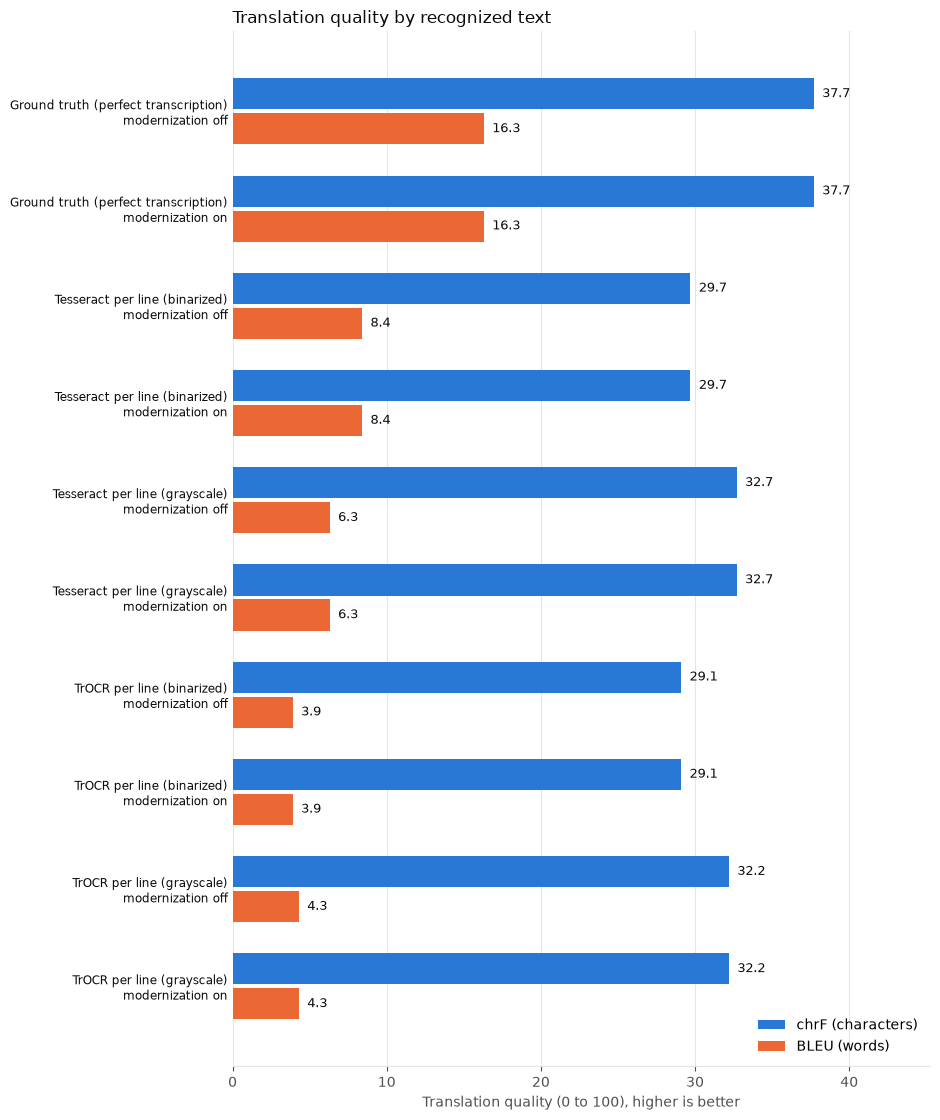

In [10]:
if reference and not results.empty:
    BLUE, ORANGE = "#2a78d6", "#eb6834"          # validated categorical pair from the dataviz palette
    INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

    labels = [f"{r['Source text']}\nmodernization {r['Spelling modernization'].lower()}" for _, r in results.iterrows()]
    y = np.arange(len(results))
    h = 0.36
    fig, ax = plt.subplots(figsize=(9.5, 0.95 * len(results) + 1.8))
    b1 = ax.barh(y - h / 2, results["chrF"], h - 0.04, color=BLUE, label="chrF (characters)")
    b2 = ax.barh(y + h / 2, results["BLEU"], h - 0.04, color=ORANGE, label="BLEU (words)")
    xmax = max(results[["chrF", "BLEU"]].max().max(), 1) * 1.2
    for bars in (b1, b2):
        for bar in bars:
            ax.text(bar.get_width() + xmax * 0.012, bar.get_y() + bar.get_height() / 2,
                    f"{bar.get_width():.1f}", va="center", fontsize=9, color=INK)
    ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8.5, color=INK)
    ax.invert_yaxis()
    ax.set_xlim(0, xmax)
    ax.set_xlabel("Translation quality (0 to 100), higher is better", color=MUTED)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(axis="x", colors=MUTED); ax.tick_params(axis="y", length=0)
    ax.set_title("Translation quality by recognized text", loc="left", color=INK, fontsize=12)
    ax.legend(frameon=False, loc="lower right")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "comparison.png"), dpi=200)
    plt.show()
else:
    if not translations:
        print("Chart skipped: no translations were produced. The model was not loaded in Step 4 (read the message there;")
        print("usually torch or transformers is not installed, or there is no internet for the first download).")
    else:
        print("Chart skipped: no reference translation was loaded (see the message in Step 2).")

## Step 8. Read the translations
Numbers hide what went wrong. Read the passages next to the reference, and look for old words the model left untranslated or got wrong. These make good examples for the paper's error analysis.

In [11]:
if translations:
    pd.set_option("display.max_colwidth", 400)
    passages = pd.DataFrame([
        {"Source text": n, "Modernization": "On" if m else "Off", "Translation": t,
         "Spelling changes made": ", ".join(change_log[(n, m)]) if m else ""}
        for (n, m), t in translations.items()])
    if reference:
        passages = pd.concat([pd.DataFrame([{"Source text": "REFERENCE (human)", "Modernization": "", "Translation": reference,
                                             "Spelling changes made": ""}]), passages], ignore_index=True)
    passages.to_csv(os.path.join(OUT_DIR, "translations.csv"), index=False)
    display(passages)
else:
    print("Nothing to show: no translations were produced. The model was not loaded in Step 4 (read the message there).")

,Source text,Modernization,Translation,Spelling changes made
0,REFERENCE (human),,"Nuestra entrada sera presidida por la bandera Nacional Fili- pina con uniformes y estrellas correspondientes. Dios gda. a.v.m.s.a.s. Cuartel Grl. de Taban 25 de Marzo de 1901. El Gral. de Brigada (Signado) Ludovico Arejola On March 25, 1901, General Arejola announced to all inhabitants of Ambos Camarines and Catanduanes the following: ""Mis queridos paisanos y compatriotas: Nadie de vosotros pu...",
1,Ground truth (perfect transcription),Off,"Our entrance will be presided by the Philippine National flag with uniforms and corresponding stars. God gda. a.v.m.a.s. Headquarters Grl. de Taban March 25, 1901. The Brigadier General (Signado) Ludovico Arejola On March 25, 1901, General Arejola announced to all inhabitants of Both Camarines and Catanduanes the following: ""My dear countrymen and compatriots: No one of you can ignore that I, ...",
2,Ground truth (perfect transcription),On,"Our entrance will be presided by the Philippine National flag with uniforms and corresponding stars. God gda. a.v.m.a.s. Headquarters Grl. de Taban March 25, 1901. The Brigadier General (Signado) Ludovico Arejola On March 25, 1901, General Arejola announced to all inhabitants of Both Camarines and Catanduanes the following: ""My dear countrymen and compatriots: No one of you can ignore that I, ...",
3,Tesseract per line (binarized),Off,"Oco a-. “or 2. 9 = IO an > A Fuestra entry will be presided over by the handmaiden Razione : Fili- La pina with uwmiformes and corresponding stars, 5) God gde. 8.7.M.8.5. Barracks (ri, de Taban 25 de Marzo de 1901, (> El Gral, de Brigadier (Big Mo) Ludovico Arejola On March 25, 1901, Úenerz wnaced to ell, 1ecltante , Arejola. 0f Both Camarines and Catanduanes the following; *mMore beloved and ...",
4,Tesseract per line (binarized),On,"Oco a-. “or 2. 9 = IO an > A Fuestra entry will be presided over by the handmaiden Razione : Fili- La pina with uwmiformes and corresponding stars, 5) God gde. 8.7.M.8.5. Barracks (ri, de Taban 25 de Marzo de 1901, (> El Gral, de Brigadier (Big Mo) Ludovico Arejola On March 25, 1901, Úenerz wnaced to ell, 1ecltante , Arejola. 0f Both Camarines and Catanduanes the following; *mMore beloved and ...",
5,Tesseract per line (grayscale),Off,"o? o? o 2.9 +0 = ENS vr ) ad Our entrance will be presided over by the flag Nations. Plli= Pina with uniforms and corresponding stars, And God gda. 2.V.M.8,8,8.Grl headquarters, from ""abando 25 de Marzo de 1901. lr El Gral, de Prigads» (Sig do) Ludovico Arejola On March 25,1901, Generates wounced to all, 1abltant Arejols"" : from Both Camarines aná Catanduanes the following: ""My dear and ¡isano...",
6,Tesseract per line (grayscale),On,"o? o? o 2.9 +0 = ENS vr ) ad Our entrance will be presided over by the flag Nations. Plli= Pina with uniforms and corresponding stars, And God gda. 2.V.M.8,8,8.Grl headquarters, from ""abando 25 de Marzo de 1901. lr El Gral, de Prigads» (Sig do) Ludovico Arejola On March 25,1901, Generates wounced to all, 1abltant Arejols"" : from Both Camarines aná Catanduanes the following: ""My dear and ¡isano...",
7,TrOCR per line (binarized),Off,"000 0.0000 "" 2 ) I 9 . 2nd Kuestra entry to be presided over by the handmaiden Racione : PILLLpins with uniforms and corresponding stars . "" DLOS EAS. B.F.M.S.B.S. Quartet Orl. de Raben 25 March 1901 . er El Gral . do Brigade (81ndel Ludovico Angola On March 25 1901 , Oeners , was loved to all : abitants . "" Aregois . of Arbor Canarines and Catanduanes the following : while dear friends ; clea...",
8,TrOCR per line (binarized),On,"000 0.0000 "" 2 ) I 9 . 2nd Kuestra entry to be presided over by the handmaiden Racione : PILLLpins with uniforms and corresponding stars . "" DLOS EAS. B.F.M.S.B.S. Quartet Orl. de Raben 25 March 1901 . er El Gral . do Brigade (81ndel Ludovico Angola On March 25 1901 , Oeners , was loved to all : abitants . "" Aregois . of Arbor Canarines and Catanduanes the following : while dear 

## Step 9. Save everything

In [12]:
for (name, modernize_on), hyp in translations.items():
    safe = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
    fname = f"{safe}__modernized_{'on' if modernize_on else 'off'}.txt"
    with open(os.path.join(OUT_DIR, fname), "w", encoding="utf-8") as f:
        f.write(hyp)
print("Saved to", OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

Saved to ../outputs/translation
['comparison.png', 'ground_truth_perfect_transcription__modernized_off.txt', 'ground_truth_perfect_transcription__modernized_on.txt', 'results.csv', 'tesseract_per_line_binarized__modernized_off.txt', 'tesseract_per_line_binarized__modernized_on.txt', 'tesseract_per_line_grayscale__modernized_off.txt', 'tesseract_per_line_grayscale__modernized_on.txt', 'translations.csv', 'trocr_per_line_binarized__modernized_off.txt', 'trocr_per_line_binarized__modernized_on.txt', 'trocr_per_line_grayscale__modernized_off.txt', 'trocr_per_line_grayscale__modernized_on.txt']


## What to report in the paper

1. **Method:** pretrained Marian model (`opus-mt-es-en`), recognized lines joined into passages, with and without a rule-based spelling modernization step; scores are BLEU and chrF against a human reference translation.
2. **Table:** `results.csv`. The *chrF vs perfect input* column shows how much recognition errors reduce translation quality.
3. **Figure:** `comparison.png`, and example passages from `translations.csv` for the error analysis.
4. **Discussion points:**
   - Does modernizing old spellings help the translation? (Compare the On and Off rows.)
   - How much quality is lost because of recognition errors, compared with the perfect transcription?
   - Which period words or expressions does the model get wrong? This motivates fine-tuning on your own parallel text, as in the related studies on low-resource and pretrained translation.
5. **Limits to state:** the size of the test set, who wrote the reference translation, that the translation model was trained on modern Spanish, and that the modernization table is only a starter list.